In [ ]:
%cd /content/HVI-CIDNet

!pwd
!git status --short
!ls

[Errno 2] No such file or directory: '/content/HVI-CIDNet'
/content
/content
fatal: not a git repository (or any of the parent directories): .git
sample_data


In [ ]:
import os

print("Current directory:", os.getcwd())
print("\nFiles inside /content:")

for item in os.listdir("/content"):
    print(item)

Current directory: /content

Files inside /content:
.config
sample_data


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    if "train.py" in files and "eval.py" in files:
        print("Original repository candidate:", root)

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
%cd /content

!git clone https://github.com/Fediory/HVI-CIDNet.git

/content
Cloning into 'HVI-CIDNet'...
remote: Enumerating objects: 335, done.
remote: Counting objects: 100% (186/186), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 335 (delta 164), reused 148 (delta 148), pack-reused 149 (from 3)
Receiving objects: 100% (335/335), 46.58 MiB | 29.40 MiB/s, done.
Resolving deltas: 100% (188/188), done.


In [ ]:
%cd /content/HVI-CIDNet

!ls
!ls net
!ls data
!ls loss

/content/HVI-CIDNet
app.py	    eval_SID_blur.py	  measure.py	       pic
data	    LICENSE		  measure_SID_blur.py  Readme.md
eval_hf.py  loss		  net		       requirements.txt
eval.py     measure_niqe_bris.py  net_test.py	       train.py
CIDNet.py  HVI_transform.py  LCA.py  transformer_utils.py
data.py       fivek.py	     options.py    SICE_blur_SID.py
eval_sets.py  LOLdataset.py  scheduler.py  util.py
losses.py  loss_utils.py  niqe_pris_params.npz	niqe_utils.py  vgg_arch.py


In [ ]:
%cd /content/HVI-CIDNet

!cat requirements.txt

/content/HVI-CIDNet
arch==5.3.1
image_quality==1.2.7
lpips==0.1.4
matplotlib==3.5.3
numpy
opencv_contrib_python==4.7.0.72
Pillow==9.5.0
scipy==1.7.3
thop
torch==1.13.1
torchvision==0.14.1
tqdm==4.65.0
einops==0.6.1
lpips==0.1.4
opencv-python
gradio
huggingface_hub
safetensors

In [ ]:
%cd /content/HVI-CIDNet

!ls
!cat README.md

/content/HVI-CIDNet
app.py	    eval_SID_blur.py	  measure.py	       pic
data	    LICENSE		  measure_SID_blur.py  Readme.md
eval_hf.py  loss		  net		       requirements.txt
eval.py     measure_niqe_bris.py  net_test.py	       train.py
cat: README.md: No such file or directory


In [ ]:
%cd /content/HVI-CIDNet

!sed -n '1,240p' eval.py
!sed -n '1,240p' measure.py

/content/HVI-CIDNet
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
import argparse
from tqdm import tqdm
from data.data import *
from torchvision import transforms
from torch.utils.data import DataLoader
from loss.losses import *
from net.CIDNet import CIDNet


def eval(model, testing_data_loader, model_path, output_folder,norm_size=True,LOL=False,v2=False,unpaired=False,alpha=1.0,gamma=1.0):
    torch.set_grad_enabled(False)
    model.load_state_dict(torch.load(model_path, map_location=lambda storage, loc: storage))
    print('Pre-trained model is loaded.')
    model.eval()
    print('Evaluation:')
    if LOL:
        model.trans.gated = True
    elif v2:
        model.trans.gated2 = True
        model.trans.alpha = alpha
    elif unpaired:
        model.trans.gated2 = True
        model.trans.alpha = alpha
    for batch in tqdm(testing_data_loader):
        with torch.no_grad():
            if norm_size:
                input, name = batch[0], batch[1]
            else:
         

In [ ]:
%cd /content/HVI-CIDNet

!ls

/content/HVI-CIDNet
app.py	    eval_SID_blur.py	  measure.py	       pic
data	    LICENSE		  measure_SID_blur.py  Readme.md
eval_hf.py  loss		  net		       requirements.txt
eval.py     measure_niqe_bris.py  net_test.py	       train.py


In [ ]:
!find . -maxdepth 3 -type f \
  \( -name "eval.py" -o -name "measure.py" \
  -o -name "train.py" -o -name "*.pth" \
  -o -name "*.safetensors" \)

./train.py
./eval.py
./measure.py


In [ ]:
%cd /content/HVI-CIDNet

!sed -n '1,240p' eval.py

/content/HVI-CIDNet
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
import argparse
from tqdm import tqdm
from data.data import *
from torchvision import transforms
from torch.utils.data import DataLoader
from loss.losses import *
from net.CIDNet import CIDNet


def eval(model, testing_data_loader, model_path, output_folder,norm_size=True,LOL=False,v2=False,unpaired=False,alpha=1.0,gamma=1.0):
    torch.set_grad_enabled(False)
    model.load_state_dict(torch.load(model_path, map_location=lambda storage, loc: storage))
    print('Pre-trained model is loaded.')
    model.eval()
    print('Evaluation:')
    if LOL:
        model.trans.gated = True
    elif v2:
        model.trans.gated2 = True
        model.trans.alpha = alpha
    elif unpaired:
        model.trans.gated2 = True
        model.trans.alpha = alpha
    for batch in tqdm(testing_data_loader):
        with torch.no_grad():
            if norm_size:
                input, name = batch[0], batch[1]
            else:
         

In [ ]:
%cd /content/HVI-CIDNet

!find . -type f \( \
  -name "*.pth" -o \
  -name "*.pt" -o \
  -name "*.ckpt" -o \
  -name "*.safetensors" \
\)

/content/HVI-CIDNet


In [ ]:
%cd /content/HVI-CIDNet

!grep -inE "pretrain|checkpoint|weight|eval.py|measure.py|LOL" README.md

/content/HVI-CIDNet
grep: README.md: No such file or directory


In [ ]:
%cd /content/HVI-CIDNet

!ls -la

/content/HVI-CIDNet
total 124
drwxr-xr-x 7 root root  4096 Oct 13 23:30 .
drwxr-xr-x 1 root root  4096 Oct 13 23:30 ..
-rw-r--r-- 1 root root  3697 Oct 13 23:30 app.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 data
-rw-r--r-- 1 root root  2706 Oct 13 23:30 eval_hf.py
-rw-r--r-- 1 root root  7761 Oct 13 23:30 eval.py
-rw-r--r-- 1 root root  2823 Oct 13 23:30 eval_SID_blur.py
drwxr-xr-x 8 root root  4096 Oct 13 23:30 .git
-rw-r--r-- 1 root root  3119 Oct 13 23:30 .gitignore
-rw-r--r-- 1 root root  1068 Oct 13 23:30 LICENSE
drwxr-xr-x 2 root root  4096 Oct 13 23:30 loss
-rw-r--r-- 1 root root  1595 Oct 13 23:30 measure_niqe_bris.py
-rw-r--r-- 1 root root  5338 Oct 13 23:30 measure.py
-rw-r--r-- 1 root root  5994 Oct 13 23:30 measure_SID_blur.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 net
-rw-r--r-- 1 root root   543 Oct 13 23:30 net_test.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 pic
-rw-r--r-- 1 root root 25902 Oct 13 23:30 Readme.md
-rw-r--r-- 1 root root   256 Oct 13 23:30 requirem

In [ ]:
!find . -maxdepth 2 -iname "*readme*"

./Readme.md


In [ ]:
%cd /content/HVI-CIDNet
!ls -la

/content/HVI-CIDNet
total 124
drwxr-xr-x 7 root root  4096 Oct 13 23:30 .
drwxr-xr-x 1 root root  4096 Oct 13 23:30 ..
-rw-r--r-- 1 root root  3697 Oct 13 23:30 app.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 data
-rw-r--r-- 1 root root  2706 Oct 13 23:30 eval_hf.py
-rw-r--r-- 1 root root  7761 Oct 13 23:30 eval.py
-rw-r--r-- 1 root root  2823 Oct 13 23:30 eval_SID_blur.py
drwxr-xr-x 8 root root  4096 Oct 13 23:30 .git
-rw-r--r-- 1 root root  3119 Oct 13 23:30 .gitignore
-rw-r--r-- 1 root root  1068 Oct 13 23:30 LICENSE
drwxr-xr-x 2 root root  4096 Oct 13 23:30 loss
-rw-r--r-- 1 root root  1595 Oct 13 23:30 measure_niqe_bris.py
-rw-r--r-- 1 root root  5338 Oct 13 23:30 measure.py
-rw-r--r-- 1 root root  5994 Oct 13 23:30 measure_SID_blur.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 net
-rw-r--r-- 1 root root   543 Oct 13 23:30 net_test.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 pic
-rw-r--r-- 1 root root 25902 Oct 13 23:30 Readme.md
-rw-r--r-- 1 root root   256 Oct 13 23:30 requirem

In [ ]:
%cd /content/HVI-CIDNet

!cat Readme.md

/content/HVI-CIDNet
&nbsp;

<p align="center"> <img src="pic/logo.png" width="500px"> </p>

# [CVPR2025] HVI: A New Color Space for Low-light Image Enhancement

**[Qingsen Yan](https://scholar.google.com/citations?user=BSGy3foAAAAJ)<sup>∗ </sup>, [Yixu Feng](https://scholar.google.com/citations?user=WljJ2HUAAAAJ)<sup>∗ </sup>, [Cheng Zhang](https://scholar.google.com/citations?user=L_Av9NcAAAAJ)**,  [Guansong Pang](https://scholar.google.com/citations?user=1ZO7pHkAAAAJ), Kangbiao Shi, [Peng Wu](https://scholar.google.com/citations?user=QkNqUH4AAAAJ), Wei Dong, Jinqiu Sun,  [Yanning Zhang](https://scholar.google.com/citations?user=-wzlS7QAAAAJ)

Previous Version: [You Only Need One Color Space: An Efficient Network for Low-light Image Enhancement](https://arxiv.org/abs/2402.05809)

<div align="center">
	
[![arXiv](https://img.shields.io/badge/arXiv-Paper-red.svg)](https://arxiv.org/abs/2502.20272)
[![Gradio Spaces](https://img.shields.io/badge/%F0%9F%A4%97%20Gradio%20-Spaces-violet)](ht

In [ ]:
!grep -inE "install|pretrain|checkpoint|weight|eval|measure|dataset|train|LOL" Readme.md

33:- **2025.06.03** Special Thanks for Kangbiao Shi for training HVI-CIDNet on FiveK dataset follow retinexformer. The training code and models are avaliable now. 🔆
36:- **2025.03.10** All weights are public at [Hugging Face](https://huggingface.co/papers/2502.20272). Special Thanks to [Niels Rogge](https://github.com/NielsRogge), [Wauplin](https://github.com/Wauplin), and [hysts](https://huggingface.co/hysts).🔆
39:- **2025.01.31** Update train code. Use random gamma function (enhancement curve) to improve cross-dataset generalization. 🔆
41:- **2024.05.12** Update peer results on LOLv1. 🤝
42:- **2024.04.28** Synchronize all Baidu Pan datasets, outputs, and weights to One Drive. 🌎
43:- **2024.04.18** Full version Code, models, visual comparison have been released. We promise that all the weights only trained on train sets, and each weights is reproducible. Hope it will help your future work. If you have trained a better result, please contact us. We look forward to subsequent work based

In [ ]:
%cd /content/HVI-CIDNet

!sed -n '350,475p' Readme.md

/content/HVI-CIDNet

- **You can test our method in our gradio demo with bash code `python app.py`, and go to the URL link "http://127.0.0.1:7862" to enjoy the demo.** (add `--cpu` can inference CPU-only)
- or You can use `huggingface_hub` to download and test our method as:
```bash
# you can find all weights in https://huggingface.co/papers/2502.20272
python eval_hf.py --path fediory/our_model_path --input_img your/img/path --alpha_s 1.0 --alpha_i 1.0 --gamma 1.0

# for example
python eval_hf.py --path fediory/HVI-CIDNet-LOLv1-wperc --input_img ./datasets/DICM/01.JPG --alpha_s 1.0 --alpha_i 1.0 --gamma 1.0
```
and your enhanced image will be saved at `./output_hf`.

- or **You can test our method as followed, all the results will saved in `./output` folder:**

<details close> <summary>(click to expand)</summary>

```bash
# LOLv1
python eval.py --lol --perc # weights that trained with perceptual loss
python eval.py --lol # weights that trained without perceptual loss

# LOLv2-real
pyth

In [ ]:
%cd /content/HVI-CIDNet

!find . -type f \( \
  -name "*.pth" -o \
  -name "*.pt" -o \
  -name "*.ckpt" -o \
  -name "*.safetensors" \
\)

/content/HVI-CIDNet


In [ ]:
!grep -nE "lol_v1|lolv2_real|lolv2_syn|epoch|batch_size|learning_rate|lr" data/options.py

16:    parser.add_argument('--nEpochs', type=int, default=1000, help='number of epochs to train for end')
17:    parser.add_argument('--start_epoch', type=int, default=0, help='number of epochs to start, >0 is retrained a pre-trained pth')
19:    parser.add_argument('--lr', type=float, default=1e-4, help='Learning Rate')
29:    parser.add_argument('--warmup_epochs', type=int, default=3, help='warmup_epochs')
34:    parser.add_argument('--data_train_lol_v1'       , type=str, default='./datasets/LOLdataset/our485')
35:    parser.add_argument('--data_train_lolv2_real'   , type=str, default='./datasets/LOLv2/Real_captured/Train')
36:    parser.add_argument('--data_train_lolv2_syn'    , type=str, default='./datasets/LOLv2/Synthetic/Train')
43:    parser.add_argument('--data_val_lol_v1'         , type=str, default='./datasets/LOLdataset/eval15/low')
44:    parser.add_argument('--data_val_lolv2_real'     , type=str, default='./datasets/LOLv2/Real_captured/Test/Low')
45:    parser.add_argument

In [ ]:
%cd /content/HVI-CIDNet

print("=== Checkpoint files ===")
!find . -type f \( -name "*.pth" -o -name "*.pt" -o -name "*.ckpt" -o -name "*.safetensors" \)

print("\n=== Weight directories ===")
!find . -maxdepth 3 -type d | grep -E "weight|checkpoint|pretrain"


/content/HVI-CIDNet
=== Checkpoint files ===

=== Weight directories ===


In [ ]:
!sed -n '370,455p' Readme.md


# LOLv2-real
python eval.py --lol_v2_real --best_GT_mean # you can choose best_GT_mean or best_PSNR or best_SSIM

# LOLv2-syn
python eval.py --lol_v2_syn --perc # weights that trained with perceptual loss
python eval.py --lol_v2_syn # weights that trained without perceptual loss

# SICE
python eval.py --SICE_grad # output SICE_grad
python eval.py --SICE_mix # output SICE_mix

# FiveK
python eval.py --fivek # output FiveK follow Retinexformer

# Sony-Total-Dark
python eval_SID_blur --SID

# LOL-Blur
python eval_SID_blur --Blur

# five unpaired datasets DICM, LIME, MEF, NPE, VV. 
# We note that: you can choose one weights in ./weights folder, and set the alpha float number (defualt=1.0) as illumination scale of the datasets.
# gamma denotes the gamma function (curve), see line 59 of "eval.py"
# You can change "--DICM" to the other unpaired datasets "LIME, MEF, NPE, VV".
python eval.py --unpaired --DICM --unpaired_weights --alpha
# e.g.
python eval.py --unpaired --DICM --unpaired_weights

In [ ]:
%cd /content/HVI-CIDNet

print("=== Model and checkpoint files ===")
!find . -type f \( -name "*.pth" -o -name "*.pt" -o -name "*.ckpt" -o -name "*.safetensors" \)

print("\n=== Model testing script ===")
!ls net_test.py eval.py measure.py train.py

/content/HVI-CIDNet
=== Model and checkpoint files ===

=== Model testing script ===
eval.py  measure.py  net_test.py  train.py


In [ ]:
%cd /content/HVI-CIDNet

!sed -n '1,180p' eval_hf.py

/content/HVI-CIDNet
from net.CIDNet import CIDNet
import os
import json
import safetensors.torch as sf
from huggingface_hub import hf_hub_download
import argparse
import torchvision.transforms as transforms
import torch.nn.functional as F
import torch
import platform
from PIL import Image


def from_pretrained(cls, pretrained_model_name_or_path: str):
    model_id = str(pretrained_model_name_or_path)

    config_file = hf_hub_download(repo_id=model_id, filename="config.json", repo_type="model")
    config = None
    if config_file is not None:
        with open(config_file, "r", encoding="utf-8") as f:
            config = json.load(f)


    model_file = hf_hub_download(repo_id=model_id, filename="model.safetensors", repo_type="model")
    # instance = sf.load_model(cls, model_file, strict=False)
    state_dict  = sf.load_file(model_file)
    cls.load_state_dict(state_dict, strict=False) 
    return cls


if __name__ == '__main__':

    eval_parser = argparse.ArgumentParser(description

In [ ]:
!sed -n '1,180p' eval.py

import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
import argparse
from tqdm import tqdm
from data.data import *
from torchvision import transforms
from torch.utils.data import DataLoader
from loss.losses import *
from net.CIDNet import CIDNet


def eval(model, testing_data_loader, model_path, output_folder,norm_size=True,LOL=False,v2=False,unpaired=False,alpha=1.0,gamma=1.0):
    torch.set_grad_enabled(False)
    model.load_state_dict(torch.load(model_path, map_location=lambda storage, loc: storage))
    print('Pre-trained model is loaded.')
    model.eval()
    print('Evaluation:')
    if LOL:
        model.trans.gated = True
    elif v2:
        model.trans.gated2 = True
        model.trans.alpha = alpha
    elif unpaired:
        model.trans.gated2 = True
        model.trans.alpha = alpha
    for batch in tqdm(testing_data_loader):
        with torch.no_grad():
            if norm_size:
                input, name = batch[0], batch[1]
            else:
                input, name, 

In [ ]:
%cd /content/HVI-CIDNet

!sed -n '1,180p' eval_hf.py


/content/HVI-CIDNet
from net.CIDNet import CIDNet
import os
import json
import safetensors.torch as sf
from huggingface_hub import hf_hub_download
import argparse
import torchvision.transforms as transforms
import torch.nn.functional as F
import torch
import platform
from PIL import Image


def from_pretrained(cls, pretrained_model_name_or_path: str):
    model_id = str(pretrained_model_name_or_path)

    config_file = hf_hub_download(repo_id=model_id, filename="config.json", repo_type="model")
    config = None
    if config_file is not None:
        with open(config_file, "r", encoding="utf-8") as f:
            config = json.load(f)


    model_file = hf_hub_download(repo_id=model_id, filename="model.safetensors", repo_type="model")
    # instance = sf.load_model(cls, model_file, strict=False)
    state_dict  = sf.load_file(model_file)
    cls.load_state_dict(state_dict, strict=False) 
    return cls


if __name__ == '__main__':

    eval_parser = argparse.ArgumentParser(description

In [ ]:
!sed -n '1,100p' eval.py


import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
import argparse
from tqdm import tqdm
from data.data import *
from torchvision import transforms
from torch.utils.data import DataLoader
from loss.losses import *
from net.CIDNet import CIDNet


def eval(model, testing_data_loader, model_path, output_folder,norm_size=True,LOL=False,v2=False,unpaired=False,alpha=1.0,gamma=1.0):
    torch.set_grad_enabled(False)
    model.load_state_dict(torch.load(model_path, map_location=lambda storage, loc: storage))
    print('Pre-trained model is loaded.')
    model.eval()
    print('Evaluation:')
    if LOL:
        model.trans.gated = True
    elif v2:
        model.trans.gated2 = True
        model.trans.alpha = alpha
    elif unpaired:
        model.trans.gated2 = True
        model.trans.alpha = alpha
    for batch in tqdm(testing_data_loader):
        with torch.no_grad():
            if norm_size:
                input, name = batch[0], batch[1]
            else:
                input, name, 

In [ ]:
%cd /content/HVI-CIDNet

!grep -n -E "unpaired_weights|best_PSNR|best_SSIM|w_perc|wo_perc|load_state_dict|torch.load|output_folder|add_argument.*weights" eval.py

/content/HVI-CIDNet
12:def eval(model, testing_data_loader, model_path, output_folder,norm_size=True,LOL=False,v2=False,unpaired=False,alpha=1.0,gamma=1.0):
14:    model.load_state_dict(torch.load(model_path, map_location=lambda storage, loc: storage))
36:        if not os.path.exists(output_folder):          
37:            os.mkdir(output_folder)  
44:        output_img.save(output_folder + name[0])
65:    eval_parser.add_argument('--best_PSNR', action='store_true', help='output lol_v2_real dataset best_PSNR')
66:    eval_parser.add_argument('--best_SSIM', action='store_true', help='output lol_v2_real dataset best_SSIM')
78:    eval_parser.add_argument('--unpaired_weights', type=str, default='./weights/LOLv2_syn/w_perc.pth')
95:        output_folder = './output/LOLv1/'
97:            weight_path = './weights/LOLv1/w_perc.pth'
99:            weight_path = './weights/LOLv1/wo_perc.pth'
104:        output_folder = './output/LOLv2_real/'
106:            weight_path = './weights/LOLv2_rea

In [ ]:
!ls -l eval_hf.py

-rw-r--r-- 1 root root 2706 Oct 13 23:30 eval_hf.py


In [ ]:
!sed -n '1,180p' eval_hf.py

from net.CIDNet import CIDNet
import os
import json
import safetensors.torch as sf
from huggingface_hub import hf_hub_download
import argparse
import torchvision.transforms as transforms
import torch.nn.functional as F
import torch
import platform
from PIL import Image


def from_pretrained(cls, pretrained_model_name_or_path: str):
    model_id = str(pretrained_model_name_or_path)

    config_file = hf_hub_download(repo_id=model_id, filename="config.json", repo_type="model")
    config = None
    if config_file is not None:
        with open(config_file, "r", encoding="utf-8") as f:
            config = json.load(f)


    model_file = hf_hub_download(repo_id=model_id, filename="model.safetensors", repo_type="model")
    # instance = sf.load_model(cls, model_file, strict=False)
    state_dict  = sf.load_file(model_file)
    cls.load_state_dict(state_dict, strict=False) 
    return cls


if __name__ == '__main__':

    eval_parser = argparse.ArgumentParser(description='EvalHF')
    eval_

In [ ]:
%cd /content/HVI-CIDNet

!grep -n -E "unpaired_weights|weight_path|LOLv1|load_state_dict" eval.py

/content/HVI-CIDNet
14:    model.load_state_dict(torch.load(model_path, map_location=lambda storage, loc: storage))
78:    eval_parser.add_argument('--unpaired_weights', type=str, default='./weights/LOLv2_syn/w_perc.pth')
95:        output_folder = './output/LOLv1/'
97:            weight_path = './weights/LOLv1/w_perc.pth'
99:            weight_path = './weights/LOLv1/wo_perc.pth'
106:            weight_path = './weights/LOLv2_real/w_perc.pth'
109:            weight_path = './weights/LOLv2_real/best_PSNR.pth'
112:            weight_path = './weights/LOLv2_real/best_SSIM.pth'
119:            weight_path = './weights/LOLv2_syn/w_perc.pth'
121:            weight_path = './weights/LOLv2_syn/wo_perc.pth'
126:        weight_path = './weights/SICE.pth'
132:        weight_path = './weights/SICE.pth'
138:        weight_path = './weights/fivek.pth'
162:        weight_path = ep.unpaired_weights
165:    eval(eval_net, eval_data, weight_path, output_folder,norm_size=norm_size,LOL=ep.lol,v2=ep.lol_v

In [ ]:
%cd /content/HVI-CIDNet

!find weights -maxdepth 3 -type f 2>/dev/null

/content/HVI-CIDNet


In [ ]:
!ls -la
!grep -n -i -E "huggingface|weight|checkpoint|onedrive|baidu" Readme.md

total 124
drwxr-xr-x 7 root root  4096 Oct 13 23:30 .
drwxr-xr-x 1 root root  4096 Oct 13 23:30 ..
-rw-r--r-- 1 root root  3697 Oct 13 23:30 app.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 data
-rw-r--r-- 1 root root  2706 Oct 13 23:30 eval_hf.py
-rw-r--r-- 1 root root  7761 Oct 13 23:30 eval.py
-rw-r--r-- 1 root root  2823 Oct 13 23:30 eval_SID_blur.py
drwxr-xr-x 8 root root  4096 Oct 13 23:30 .git
-rw-r--r-- 1 root root  3119 Oct 13 23:30 .gitignore
-rw-r--r-- 1 root root  1068 Oct 13 23:30 LICENSE
drwxr-xr-x 2 root root  4096 Oct 13 23:30 loss
-rw-r--r-- 1 root root  1595 Oct 13 23:30 measure_niqe_bris.py
-rw-r--r-- 1 root root  5338 Oct 13 23:30 measure.py
-rw-r--r-- 1 root root  5994 Oct 13 23:30 measure_SID_blur.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 net
-rw-r--r-- 1 root root   543 Oct 13 23:30 net_test.py
drwxr-xr-x 2 root root  4096 Oct 13 23:30 pic
-rw-r--r-- 1 root root 25902 Oct 13 23:30 Readme.md
-rw-r--r-- 1 root root   256 Oct 13 23:30 requirements.txt
-rw-r--r-- 

In [ ]:
%cd /content/HVI-CIDNet

!find weights -maxdepth 3 -type f 2>/dev/null

/content/HVI-CIDNet


In [ ]:
%cd /content/HVI-CIDNet
!python eval.py --lol --perc

/content/HVI-CIDNet
Traceback (most recent call last):
  File "/content/HVI-CIDNet/eval.py", line 94, in <module>
    eval_data = DataLoader(dataset=get_eval_set("./datasets/LOLdataset/eval15/low"), num_workers=num_workers, batch_size=1, shuffle=False)
                                   ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/HVI-CIDNet/data/data.py", line 47, in get_eval_set
    return DatasetFromFolderEval(data_dir, transform=transform2())
  File "/content/HVI-CIDNet/data/eval_sets.py", line 38, in __init__
    data_filenames = [join(data_dir, x) for x in listdir(data_dir) if is_image_file(x)]
                                                 ~~~~~~~^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: './datasets/LOLdataset/eval15/low'


In [ ]:
%cd /content/HVI-CIDNet

!ls -la datasets
!find /content -type d -path "*/eval15/low" 2>/dev/null

/content/HVI-CIDNet
ls: cannot access 'datasets': No such file or directory


In [ ]:
%cd /content/HVI-CIDNet

!pip install -q huggingface_hub

from huggingface_hub import hf_hub_download
import os
import shutil

checkpoint = hf_hub_download(
    repo_id="Fediory/HVI-CIDNet",
    filename="weights/LOLv1/w_perc.pth"
)

os.makedirs("weights/LOLv1", exist_ok=True)
shutil.copy(checkpoint, "weights/LOLv1/w_perc.pth")

print("Checkpoint saved:", os.path.exists("weights/LOLv1/w_perc.pth"))

/content/HVI-CIDNet


weights/LOLv1/w_perc.pth: reconstructing file:   0%|          |  0.00B / 7.97MB            

weights/LOLv1/w_perc.pth: downloading bytes:           |  0.00B            

Checkpoint saved: True


In [ ]:
%cd /content/HVI-CIDNet

!ls -lh weights/LOLv1/w_perc.pth
!ls datasets/LOLdataset/eval15/low | head
!ls datasets/LOLdataset/eval15/high | head

/content/HVI-CIDNet
-r--r--r-- 1 root root 7.6M Oct 13 23:52 weights/LOLv1/w_perc.pth
ls: cannot access 'datasets/LOLdataset/eval15/low': No such file or directory
ls: cannot access 'datasets/LOLdataset/eval15/high': No such file or directory


In [ ]:
!pip -q install gdown
!gdown 157bjO1_cFuSd0HWDUuAmcHRJDVyWpOxB -O /content/LOLdataset.zip
!ls -lh /content/LOLdataset.zip

Failed to retrieve file url:

	Too many users have viewed or downloaded this file recently. Please
	try accessing the file again later. If the file you are trying to
	access is particularly large or is shared with many people, it may
	take up to 24 hours to be able to view or download the file. If you
	still can't access a file after 24 hours, contact your domain
	administrator.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=157bjO1_cFuSd0HWDUuAmcHRJDVyWpOxB

but Gdown can't. Please check connections and permissions.
ls: cannot access '/content/LOLdataset.zip': No such file or directory


In [ ]:
!mkdir -p /content/HVI-CIDNet/datasets
!unzip -q /content/LOLdataset.zip -d /content/HVI-CIDNet/datasets/
!find /content/HVI-CIDNet/datasets -maxdepth 4 -type d | head -40

unzip:  cannot find or open /content/LOLdataset.zip, /content/LOLdataset.zip.zip or /content/LOLdataset.zip.ZIP.
/content/HVI-CIDNet/datasets


In [ ]:
%cd /content/HVI-CIDNet

!git clone https://huggingface.co/datasets/saq123sa/LoL-Dataset /content/LOL-download

/content/HVI-CIDNet
Cloning into '/content/LOL-download'...
remote: Enumerating objects: 5, done.
remote: Total 5 (delta 0), reused 0 (delta 0), pack-reused 5 (from 1)
Receiving objects: 100% (5/5), done.


In [ ]:
!find /content/LOL-download -maxdepth 4 -type d
!find /content/LOL-download -type f | head -30

/content/LOL-download
/content/LOL-download/.git
/content/LOL-download/.git/hooks
/content/LOL-download/.git/info
/content/LOL-download/.git/branches
/content/LOL-download/.git/logs
/content/LOL-download/.git/logs/refs
/content/LOL-download/.git/logs/refs/heads
/content/LOL-download/.git/logs/refs/remotes
/content/LOL-download/.git/refs
/content/LOL-download/.git/refs/heads
/content/LOL-download/.git/refs/remotes
/content/LOL-download/.git/refs/remotes/origin
/content/LOL-download/.git/refs/tags
/content/LOL-download/.git/objects
/content/LOL-download/.git/objects/info
/content/LOL-download/.git/objects/pack
/content/LOL-download/README.md
/content/LOL-download/.git/hooks/applypatch-msg.sample
/content/LOL-download/.git/hooks/pre-rebase.sample
/content/LOL-download/.git/hooks/post-update.sample
/content/LOL-download/.git/hooks/push-to-checkout.sample
/content/LOL-download/.git/hooks/pre-receive.sample
/content/LOL-download/.git/hooks/update.sample
/content/LOL-download/.git/hooks/prepa

In [ ]:
!cat /content/LOL-download/README.md

---
license: unknown
tags:
- computer-vision
---

The LOL dataset is composed of 500 low-light and normal-light image pairs and is divided into 485 training pairs and 15 testing pairs. The low-light images contain noise produced during the photo capture process. Most of the images are indoor scenes. All the images have a resolution of 400×600. The dataset was introduced in the paper [Deep Retinex Decomposition for Low-Light Enhancement](https://arxiv.org/abs/1808.04560v1).

In [ ]:
import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

from huggingface_hub import list_repo_files

repo_id = "geekyrakshit/LoL-Dataset"

try:
    files = list_repo_files(repo_id, repo_type="dataset")
    print("Files found:", len(files))
    print("\n".join(files[:30]))
except Exception as e:
    print(type(e).__name__, str(e))

PyTorch: 2.11.0+cu130
GPU available: True
Files found: 3
.gitattributes
README.md
lol_dataset.zip


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
from huggingface_hub import hf_hub_download

zip_path = hf_hub_download(
    repo_id="geekyrakshit/LoL-Dataset",
    filename="lol_dataset.zip",
    repo_type="dataset"
)

print("Downloaded archive:", zip_path)

lol_dataset.zip:   0%|          | 0.00/347M [00:00<?, ?B/s]

Downloaded archive: /root/.cache/huggingface/hub/datasets--geekyrakshit--LoL-Dataset/snapshots/bdef22d0f5803da8775114496a6689333265e157/lol_dataset.zip


In [ ]:
import zipfile
import os

extract_dir = "/content/LOL-extracted"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extraction complete")

Extraction complete


In [ ]:
!find /content/LOL-extracted -maxdepth 4 -type d | head -50
!find /content/LOL-extracted -type f | head -20

/content/LOL-extracted
/content/LOL-extracted/lol_dataset
/content/LOL-extracted/lol_dataset/our485
/content/LOL-extracted/lol_dataset/our485/high
/content/LOL-extracted/lol_dataset/our485/low
/content/LOL-extracted/lol_dataset/eval15
/content/LOL-extracted/lol_dataset/eval15/high
/content/LOL-extracted/lol_dataset/eval15/low
/content/LOL-extracted/lol_dataset/our485/high/119.png
/content/LOL-extracted/lol_dataset/our485/high/565.png
/content/LOL-extracted/lol_dataset/our485/high/691.png
/content/LOL-extracted/lol_dataset/our485/high/78.png
/content/LOL-extracted/lol_dataset/our485/high/100.png
/content/LOL-extracted/lol_dataset/our485/high/583.png
/content/LOL-extracted/lol_dataset/our485/high/700.png
/content/LOL-extracted/lol_dataset/our485/high/235.png
/content/LOL-extracted/lol_dataset/our485/high/121.png
/content/LOL-extracted/lol_dataset/our485/high/658.png
/content/LOL-extracted/lol_dataset/our485/high/585.png
/content/LOL-extracted/lol_dataset/our485/high/15.png
/content/LOL-e

In [ ]:
import os
import shutil

source = "/content/LOL-extracted/lol_dataset"
destination = "/content/HVI-CIDNet/datasets/LOLdataset"

os.makedirs(os.path.dirname(destination), exist_ok=True)

if not os.path.exists(destination):
    shutil.copytree(source, destination)

print("Low-light test images:", len(os.listdir(destination + "/eval15/low")))
print("Ground-truth images:", len(os.listdir(destination + "/eval15/high")))

Low-light test images: 15
Ground-truth images: 15


In [ ]:
%cd /content/HVI-CIDNet

!ls -lh weights/LOLv1/w_perc.pth

/content/HVI-CIDNet
-r--r--r-- 1 root root 7.6M Oct 13 23:52 weights/LOLv1/w_perc.pth


In [ ]:
!python eval.py --lol --perc

Pre-trained model is loaded.
Evaluation:

===> End evaluation


In [ ]:
%cd /content/HVI-CIDNet

import os

output_dir = "output/LOLv1"
gt_dir = "datasets/LOLdataset/eval15/high"

print("Enhanced images:", len(os.listdir(output_dir)) if os.path.isdir(output_dir) else "Folder missing")
print("Ground-truth images:", len(os.listdir(gt_dir)) if os.path.isdir(gt_dir) else "Folder missing")

if os.path.isdir(output_dir):
    print("Output examples:", os.listdir(output_dir)[:10])

/content/HVI-CIDNet
Enhanced images: 15
Ground-truth images: 15
Output examples: ['179.png', '111.png', '23.png', '79.png', '22.png', '669.png', '748.png', '778.png', '55.png', '1.png']


In [ ]:
!python measure.py --lol

Traceback (most recent call last):
  File "/content/HVI-CIDNet/measure.py", line 6, in <module>
    import lpips
ModuleNotFoundError: No module named 'lpips'


In [ ]:
%pip install lpips==0.1.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 4.3 MB/s eta 0:00:00


In [ ]:
%cd /content/HVI-CIDNet
!python measure.py --lol

/content/HVI-CIDNet
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth

Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth

===> Avg.PSNR: 23.8091 dB 
===> Avg.SSIM: 0.8574 
===> Avg

In [ ]:
import os

low_dir = "/content/HVI-CIDNet/datasets/LOLdataset/eval15/low"
gt_dir = "/content/HVI-CIDNet/datasets/LOLdataset/eval15/high"
out_dir = "/content/HVI-CIDNet/output/LOLv1"

for name, path in [
    ("Low-light test", low_dir),
    ("Ground truth", gt_dir),
    ("Enhanced output", out_dir),
]:
    files = [
        f for f in os.listdir(path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ] if os.path.isdir(path) else []
    print(f"{name}: {len(files)} images")

Low-light test: 15 images
Ground truth: 15 images
Enhanced output: 15 images


In [ ]:
%cd /content/HVI-CIDNet

!sed -n '85,125p' eval.py
!sed -n '1,180p' measure.py

/content/HVI-CIDNet
        raise Exception("No GPU found, or need to change CUDA_VISIBLE_DEVICES number")
    
    if not os.path.exists('./output'):          
            os.mkdir('./output')  
    
    norm_size = True
    num_workers = 1
    alpha = None
    if ep.lol:
        eval_data = DataLoader(dataset=get_eval_set("./datasets/LOLdataset/eval15/low"), num_workers=num_workers, batch_size=1, shuffle=False)
        output_folder = './output/LOLv1/'
        if ep.perc:
            weight_path = './weights/LOLv1/w_perc.pth'
        else:
            weight_path = './weights/LOLv1/wo_perc.pth'
        
            
    elif ep.lol_v2_real:
        eval_data = DataLoader(dataset=get_eval_set("./datasets/LOLv2/Real_captured/Test/Low"), num_workers=num_workers, batch_size=1, shuffle=False)
        output_folder = './output/LOLv2_real/'
        if ep.best_GT_mean:
            weight_path = './weights/LOLv2_real/w_perc.pth'
            alpha = 0.84
        elif ep.best_PSNR:
            

In [ ]:
%cd /content/HVI-CIDNet
!sed -n '1,180p' measure.py

/content/HVI-CIDNet
import os
os.environ['CUDA_VISIBLE_DEVICES'] = "0"
import torch
import glob
import cv2
import lpips
import numpy as np
from PIL import Image
from tqdm import tqdm
import argparse
import platform



def ssim(prediction, target):
    C1 = (0.01 * 255)**2
    C2 = (0.03 * 255)**2
    img1 = prediction.astype(np.float64)
    img2 = target.astype(np.float64)
    kernel = cv2.getGaussianKernel(11, 1.5)
    window = np.outer(kernel, kernel.transpose())
    mu1 = cv2.filter2D(img1, -1, window)[5:-5, 5:-5] 
    mu2 = cv2.filter2D(img2, -1, window)[5:-5, 5:-5]
    mu1_sq = mu1**2
    mu2_sq = mu2**2
    mu1_mu2 = mu1 * mu2
    sigma1_sq = cv2.filter2D(img1**2, -1, window)[5:-5, 5:-5] - mu1_sq
    sigma2_sq = cv2.filter2D(img2**2, -1, window)[5:-5, 5:-5] - mu2_sq
    sigma12 = cv2.filter2D(img1 * img2, -1, window)[5:-5, 5:-5] - mu1_mu2
    ssim_map = ((2 * mu1_mu2 + C1) *
                (2 * sigma12 + C2)) / ((mu1_sq + mu2_sq + C1) *
                                       (si

In [ ]:
%cd /content/HVI-CIDNet
!sed -n '35,180p' measure.py

/content/HVI-CIDNet
def calculate_ssim(target, ref):
    '''
    calculate SSIM
    the same outputs as MATLAB's
    img1, img2: [0, 255]
    '''
    img1 = np.array(target, dtype=np.float64)
    img2 = np.array(ref, dtype=np.float64)
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    if img1.ndim == 2:
        return ssim(img1, img2)
    elif img1.ndim == 3:
        if img1.shape[2] == 3:
            ssims = []
            for i in range(3):
                ssims.append(ssim(img1[:, :, i], img2[:, :, i]))
            return np.array(ssims).mean()
        elif img1.shape[2] == 1:
            return ssim(np.squeeze(img1), np.squeeze(img2))
    else:
        raise ValueError('Wrong input image dimensions.')

def calculate_psnr(target, ref):
    img1 = np.array(target, dtype=np.float32)
    img2 = np.array(ref, dtype=np.float32)
    diff = img1 - img2
    psnr = 10.0 * np.log10(255.0 * 255.0 / (np.mean(np.square(diff)) + 1e-8))

In [ ]:
%cd /content/HVI-CIDNet
!python measure.py --lol

/content/HVI-CIDNet
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth

===> Avg.PSNR: 23.8091 dB 
===> Avg.SSIM: 0.8574 
===> Avg.LPIPS: 0.0856 


In [ ]:
%cd /content/HVI-CIDNet
!python measure.py --lol --use_GT_mean

/content/HVI-CIDNet
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth

===> Avg.PSNR: 27.7119 dB 
===> Avg.SSIM: 0.8759 
===> Avg.LPIPS: 0.0792 


In [ ]:

%cd /content/HVI-CIDNet

print("=== PRETRAINED CHECKPOINTS ===")
!find weights -maxdepth 3 -type f

print("\n=== DATASET FOLDERS ===")
!find datasets -maxdepth 3 -type d

print("\n=== GENERATED OUTPUTS ===")
!find output -maxdepth 2 -type d


/content/HVI-CIDNet
=== PRETRAINED CHECKPOINTS ===
weights/LOLv1/w_perc.pth

=== DATASET FOLDERS ===
datasets
datasets/LOLdataset
datasets/LOLdataset/our485
datasets/LOLdataset/our485/high
datasets/LOLdataset/our485/low
datasets/LOLdataset/eval15
datasets/LOLdataset/eval15/high
datasets/LOLdataset/eval15/low

=== GENERATED OUTPUTS ===
output
output/LOLv1


In [ ]:

%cd /content/HVI-CIDNet

import os

for folder in [
    "output/LOLv1",
    "datasets/LOLdataset/eval15/low",
    "datasets/LOLdataset/eval15/high",
]:
    print(f"\n{folder}")
    if os.path.isdir(folder):
        files = [
            f for f in os.listdir(folder)
            if os.path.isfile(os.path.join(folder, f))
        ]
        print("Image/file count:", len(files))
        print("First 5 files:", files[:5])
    else:
        print("Folder not found")


/content/HVI-CIDNet

output/LOLv1
Image/file count: 15
First 5 files: ['179.png', '111.png', '23.png', '79.png', '22.png']

datasets/LOLdataset/eval15/low
Image/file count: 15
First 5 files: ['179.png', '111.png', '23.png', '79.png', '22.png']

datasets/LOLdataset/eval15/high
Image/file count: 15
First 5 files: ['179.png', '111.png', '23.png', '79.png', '22.png']


/content/HVI-CIDNet


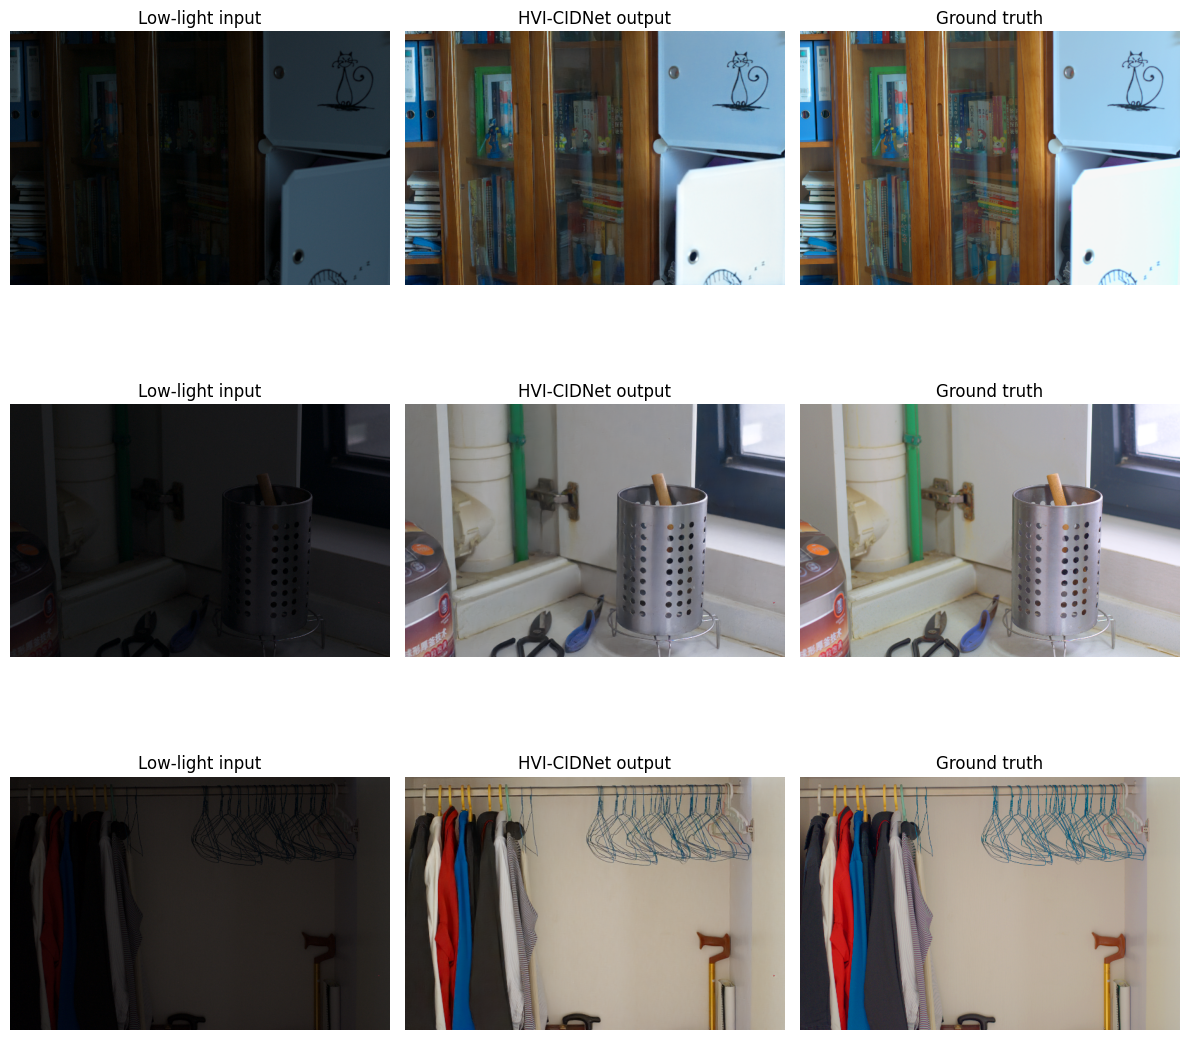

In [ ]:

%cd /content/HVI-CIDNet

import os
import matplotlib.pyplot as plt
from PIL import Image

low_dir = "datasets/LOLdataset/eval15/low"
high_dir = "datasets/LOLdataset/eval15/high"
out_dir = "output/LOLv1"

names = sorted(os.listdir(low_dir))[:3]

fig, axes = plt.subplots(len(names), 3, figsize=(12, 4 * len(names)))

for i, name in enumerate(names):
    axes[i, 0].imshow(Image.open(os.path.join(low_dir, name)))
    axes[i, 0].set_title("Low-light input")

    axes[i, 1].imshow(Image.open(os.path.join(out_dir, name)))
    axes[i, 1].set_title("HVI-CIDNet output")

    axes[i, 2].imshow(Image.open(os.path.join(high_dir, name)))
    axes[i, 2].set_title("Ground truth")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()



In [ ]:
!python measure.py --lol --use_GT_mean

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth

===> Avg.PSNR: 27.7119 dB 
===> Avg.SSIM: 0.8759 
===> Avg.LPIPS: 0.0792 
